# 03A — Validación y agrupación temática | SiteWise
Ejecutar después de 01, 01A, 02 y 03, antes del 04. Si 01A y 03 ya se ejecutaron, no hay que repetirlos.

**Objetivo:** auditar las nuevas fuentes naturales, mantener el contrato de v03 y producir una versión candidata v04 con cinco grupos y matrices para ML. No modifica v03, no entrena modelos, no imputa datos ni publica resultados en la aplicación.

**Fuentes:** [JRC](https://doi.org/10.2905/JRC.WPE5YRR), [MITECO/SNCZI](https://www.miteco.gob.es/es/cartografia-y-sig/ide/descargas/agua/descargas_agua_snczi.html), [limitaciones de cartografía MITECO](https://www.miteco.gob.es/es/agua/temas/gestion-de-los-riesgos-de-inundacion/cnih/tras-huellas-agua/aprende/zona-inundable1.html), [Civio/EGIF](https://datos.civio.es/dataset/todos-los-incendios-forestales/). JRC modeliza cuencas >150 km² y no es cartografía oficial; MITECO no cartografía todas las zonas inundables. NoData y falta de intersección no significan ausencia de peligro. Civio: incendios >=1 ha de la copia aportada, 2002–2021; superficie atribuida al municipio de origen, no superficie efectivamente quemada dentro del municipio.

**Alcance de validación:** integridad y coherencia de los indicadores; no valida el modelo hidrológico ni la aptitud de una parcela. Los nuevos indicadores quedan como candidatos, no como predictores aprobados. La licencia/atribución exacta de la copia JRC se debe confirmar antes de redistribuir datos (el catálogo presenta distintas condiciones según versión).

**Revision:** los cinco grupos se presentan como candidatos para revision conjunta Data + ML. Ninguno se selecciona por adelantado. Las alternativas son matrices de indicadores, no cinco indices compuestos definitivos.

## 1. Rutas y entradas
Solo se aceptan las salidas completas de 01A (no la carpeta de pruebas parciales). El catálogo v03 debe contener los 36 indicadores conocidos.

In [1]:
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/raw').is_dir()), None)
assert ROOT is not None, 'Abrir desde la raiz del proyecto o notebooks/'
BASE = ROOT/'data/processed/sitewise_v03'
NAT = ROOT/'data/interim/riesgos_naturales'
OUT = ROOT/'data/processed/sitewise_v04_candidata'
N = 8132
UMBRAL_COBERTURA = 98.0  # referencia exploratoria del notebook 04, no umbral de riesgo

def leer(carpeta, nombre, **kwargs):
    p = carpeta/nombre
    if not p.is_file():
        raise FileNotFoundError(f'Falta {p}. Ejecuta la etapa anterior.')
    return pd.read_csv(p, **kwargs)

municipios = leer(BASE, 'municipios.csv', dtype={'cod_ine':str,'cod_provincia':str})
ind03 = leer(BASE, 'indicadores.csv', keep_default_na=False)
val03 = leer(BASE, 'valores.csv', dtype={'cod_ine':str}, low_memory=False)
wide03 = leer(BASE, 'dataset_municipal.csv', dtype={'cod_ine':str,'cod_provincia':str}, low_memory=False)
r = leer(NAT, 'indicadores_riesgos_naturales_v01.csv', dtype={'cod_ine':str}, low_memory=False)
inventario = leer(NAT, 'inventario_fuentes_v01.csv')
geometrias = leer(NAT, 'calidad_geometrias_miteco_v01.csv')
assert set(inventario.fuente) == {'municipios','incendios','jrc_t10','jrc_t100','miteco_pb','miteco_canarias'}
assert inventario.archivo.notna().all() and inventario['modo_parcial'].astype(str).str.lower().eq('false').all(), '01A incompleto o parcial'
assert set(geometrias.fuente) == {'pb','canarias'}
assert geometrias.geometrias_originales.gt(0).all()
master = set(municipios.cod_ine)
for nombre, tabla in [('municipios',municipios),('wide03',wide03),('01A',r)]:
    assert len(tabla)==N and tabla.cod_ine.is_unique and tabla.cod_ine.str.fullmatch(r'\d{5}').all() and set(tabla.cod_ine)==master, nombre
assert len(ind03)==36 and ind03.id_indicador.is_unique
assert len(val03)==N*36 and not val03.duplicated(['cod_ine','id_indicador']).any()
assert set(val03.cod_ine)==master and set(val03.id_indicador)==set(ind03.id_indicador)
assert val03.groupby('id_indicador').size().eq(N).all()
assert val03.estado.notna().all()
assert set(ind03.id_indicador)<=set(wide03.columns)
print('Entradas completas:', N, 'municipios,',len(ind03),'indicadores originales')
display(geometrias)

Entradas completas: 8132 municipios, 36 indicadores originales


,fuente,archivo,geometrias_originales,invalidas_originales,crs,descartadas_sin_poligono,municipios_con_interseccion,tiempo_segundos
0,pb,Q100_3Ciclo_PB_20260727.shp,6222,513,"PROJCRS[""ETRS89 / UTM zone 30N"",BASEGEOGCRS[""E...",0,4059,2040.91
1,canarias,Q100_2Ciclo_Canarias_20231218_ETRS89.shp,34,9,EPSG:4083,0,27,1.34


## 2. Auditoría de riesgos naturales
Se distingue evidencia positiva de cobertura real. Las discrepancias entre modelos se contabilizan y se conservan para revisión, no se corrigen automáticamente. Las capas PB y Canarias se unen territorialmente en 01A; JRC y MITECO no se mezclan.

In [2]:
r = r.copy()
for c in [c for c in r if c.endswith('_pct')]:
    r[c] = pd.to_numeric(r[c], errors='raise')
    assert r[c].dropna().between(0,100.0001).all(), c
fire = 'incendios_ge1ha_registrados_2002_2021_n'
fire_rate = 'incendios_ge1ha_100km2_anio'
fire_area = 'superficie_incendios_origen_2002_2021_ha'
j10 = 'jrc_t10_area_positiva_pct'
j100 = 'jrc_t100_area_positiva_pct'
depth = 'jrc_t100_profundidad_positiva_media_m'
mt = 'miteco_t100_area_pct'
for c in [fire,fire_rate,fire_area,depth]:
    r[c] = pd.to_numeric(r[c],errors='raise')
    assert np.isfinite(r[c].dropna()).all() and r[c].dropna().ge(0).all(), c
assert r[fire].dropna().ge(1).all() and r[fire].dropna().mod(1).eq(0).all()
assert r.loc[r.estado_incendios.eq('sin_registros_asignados'),[fire,fire_rate,fire_area]].isna().all().all()
assert r.loc[r.miteco_t100_estado.ne('con_interseccion_cartografiada'),mt].isna().all()
assert r.loc[r.miteco_t100_estado.eq('con_interseccion_cartografiada'),mt].gt(0).all()
for t,c in [(10,j10),(100,j100)]:
    pre=f'jrc_t{t}'
    assert r.loc[r[f'{pre}_pixeles_validos'].eq(0),c].isna().all()
    assert r[f'{pre}_pixeles_positivos'].le(r[f'{pre}_pixeles_validos']).all()
    assert r[f'{pre}_pixeles_validos'].le(r[f'{pre}_pixeles_municipio']).all()
    assert r.loc[r[c].eq(0),f'{pre}_estado'].eq('cero_modelizado_en_todos_los_pixeles').all()
assert r.loc[r.jrc_t100_pixeles_positivos.eq(0),depth].isna().all()
assert (r.miteco_t100_fuente.eq('MITECO_Canarias')==r.cod_ine.str[:2].isin(['35','38'])).all()
assert ~r.miteco_t100_estado.eq('fuente_ausente_prueba').any()

# Reconciliar los registros de incendio sin volver a procesar el CSV original
fusiones=leer(NAT,'incendios_fusiones_reconciliadas.csv')
pendientes=leer(NAT,'incendios_pendientes_reconciliacion.csv')
print('Incendios asignados:',int(r[fire].sum()),'| fusiones:',len(fusiones),'| pendientes:',len(pendientes))

comparacion = r[['cod_ine',j10,j100,mt,depth,'estado_incendios','jrc_t10_estado','jrc_t100_estado','miteco_t100_estado','miteco_t100_fuente','jrc_t100_fraccion_valida_pct']].copy()
comparacion['provincia']=comparacion.cod_ine.str[:2]
a=r[j100].gt(0); b=r[mt].gt(0)
comparacion['evidencia_t100'] = np.select([a&b,a&~b,~a&b],['ambas','solo_jrc','solo_miteco'],default='sin_evidencia_positiva')
comparacion['diferencia_pp_jrc_miteco']=(r[j100]-r[mt]).where(a&b)
comparacion['t10_supera_t100']=r[j10].notna() & r[j100].notna() & (r[j10]>r[j100]+1e-6)
comparacion['incendio_registrado']=r[fire].notna()
comparacion['ambos_fenomenos']=comparacion.incendio_registrado & (a|b)
print('Comparacion de evidencia positiva T100:')
display(comparacion.evidencia_t100.value_counts().to_frame('municipios'))
print('T10 > T100 (revisar):',int(comparacion.t10_supera_t100.sum()))
print('Diferencia en puntos porcentuales (solo ambos positivos):')
display(comparacion.diferencia_pp_jrc_miteco.describe().to_frame())
prov = pd.crosstab(comparacion.provincia,comparacion.evidencia_t100).reindex(columns=['ambas','solo_jrc','solo_miteco','sin_evidencia_positiva'],fill_value=0)
prov['municipios']=prov.sum(axis=1)
display(prov.loc[prov.index.intersection(['07','35','38','51','52'])])

Incendios asignados: 94638 | fusiones: 272 | pendientes: 100
Comparacion de evidencia positiva T100:


,municipios
evidencia_t100,
ambas,3256
sin_evidencia_positiva,2298
solo_jrc,1748
solo_miteco,830


T10 > T100 (revisar): 0
Diferencia en puntos porcentuales (solo ambos positivos):


,diferencia_pp_jrc_miteco
count,3256.000000
mean,1.020482
std,7.357203
min,-57.676061
25%,-0.614824
50%,0.418845
75%,2.068710
max,90.424564


evidencia_t100,ambas,solo_jrc,solo_miteco,sin_evidencia_positiva,municipios
provincia,,,,,
07,0,0,9,58,67
35,0,0,13,21,34
38,0,0,14,40,54
51,1,0,0,0,1
52,1,0,0,0,1


## 3. Qué hacer con los huecos
No se introduce un proxy sin validar. Se calcula el déficit de cada alternativa y se etiqueta como pendiente cuando no alcanza la referencia del 98% de disponibilidad. Los indicadores naturales son históricos o modelizados; no son probabilidades de siniestro ni riesgos de parcela. Un posible proxy debe validarse espacialmente (bloques geográficos), por territorio y con error absoluto, no solo correlación.

,alternativa,municipios_con_valor,municipios_pendientes,disponibilidad_pct,decision
0,incendios_historicos,5984,2148,73.59,revisar_proxy_o_alcance
1,inundacion_jrc,5004,3128,61.53,revisar_proxy_o_alcance
2,inundacion_miteco,4086,4046,50.25,revisar_proxy_o_alcance
3,ambos_incendio_jrc,4026,4106,49.51,revisar_proxy_o_alcance
4,ambos_incendio_miteco,3214,4918,39.52,revisar_proxy_o_alcance


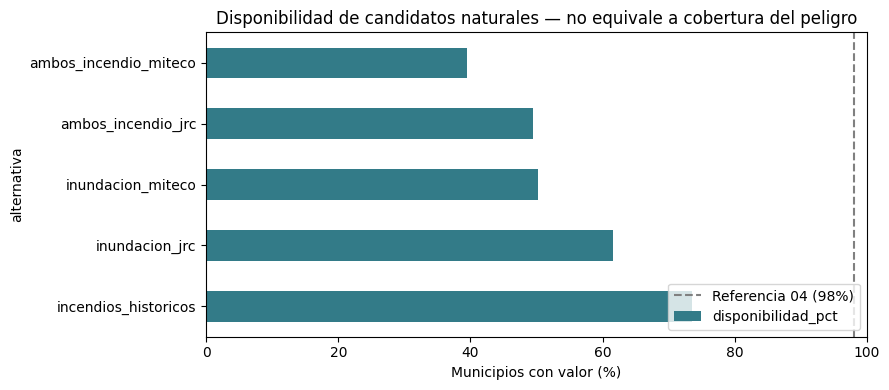

In [3]:
opciones = {'incendios_historicos':r[fire_rate].notna(), 'inundacion_jrc':r[j100].notna(), 'inundacion_miteco':r[mt].notna(), 'ambos_incendio_jrc':r[fire_rate].notna() & r[j100].notna(), 'ambos_incendio_miteco':r[fire_rate].notna() & r[mt].notna()}
proxy=pd.DataFrame([{'alternativa':k,'municipios_con_valor':int(v.sum()),'municipios_pendientes':int((~v).sum()),'disponibilidad_pct':100*v.mean(),'decision':'revisar_proxy_o_alcance' if 100*v.mean()<UMBRAL_COBERTURA else 'evaluar_calidad_y_utilidad'} for k,v in opciones.items()])
display(proxy.round(2))
ax=proxy.set_index('alternativa').disponibilidad_pct.plot.barh(figsize=(9,4),color='#337b88',xlim=(0,100))
ax.axvline(UMBRAL_COBERTURA,color='gray',linestyle='--',label='Referencia 04 (98%)')
ax.set_xlabel('Municipios con valor (%)'); ax.set_title('Disponibilidad de candidatos naturales — no equivale a cobertura del peligro'); ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

## 4. Consolidado candidato v04
Se añaden siete indicadores con identificadores nuevos; los 36 originales permanecen sin alteración. Se conservan los estados originales de 01A en un archivo auxiliar. Estados compatibles con v03: `real` para agregados históricos registrados, `aproximado_modelo` para JRC, `aproximado` para intersecciones de cartografía MITECO y `pendiente` para ausencias. Los metadatos explicitan el método y límites. No se modifica el dataset de la app.

In [4]:
CIV='https://datos.civio.es/dataset/todos-los-incendios-forestales/'
JRC='https://doi.org/10.2905/JRC.WPE5YRR'
MIT='https://www.miteco.gob.es/es/cartografia-y-sig/ide/descargas/agua/zi-lamina.html'
# id, nombre, unidad, fuente_id, organismo, URL, fecha, nivel, metodo, naturaleza, limitaciones, estado disponible, estado original
specs=[
(fire,'Incendios registrados >=1 ha, 2002–2021','incendios','civio_egif','Civio / EGIF',CIV,'2002–2021','municipio','Recuento por código INE de origen; fusiones documentadas','agregado_historico','Sin registro no equivale a cero; no incluye conatos; no mide probabilidad','real','estado_incendios'),
(fire_rate,'Incendios registrados >=1 ha por 100 km² y año','incendios/100 km²/año','civio_egif','Civio / EGIF',CIV,'2002–2021','municipio','Recuento / superficie GISCO * 100 / 20','derivado','Frecuencia histórica de origen; no riesgo futuro; sin registro queda ausente','real','estado_incendios'),
(fire_area,'Superficie quemada de incendios originados en el municipio','ha','civio_egif','Civio / EGIF',CIV,'2002–2021','municipio','Suma de superficie por municipio de origen','agregado_historico','No equivale a superficie quemada dentro del municipio; puede superar su superficie','real','estado_incendios'),
(j10,'Superficie municipal con profundidad positiva JRC T10','%','jrc_inundacion','JRC / Copernicus',JRC,'escenario T10; copia aportada 2026','raster','Píxeles centrales positivos / píxeles municipales ponderados por latitud','modelo_agregado','Cuencas >150 km²; NoData no es cero; huella positiva no cobertura completa; no cartografía oficial','aproximado_modelo','jrc_t10_estado'),
(j100,'Superficie municipal con profundidad positiva JRC T100','%','jrc_inundacion','JRC / Copernicus',JRC,'escenario T100; copia aportada 2026','raster','Píxeles centrales positivos / píxeles municipales ponderados por latitud','modelo_agregado','Cuencas >150 km²; NoData no es cero; huella positiva no cobertura completa; no cartografía oficial','aproximado_modelo','jrc_t100_estado'),
(depth,'Profundidad media de píxeles positivos JRC T100','m','jrc_inundacion','JRC / Copernicus',JRC,'escenario T100; copia aportada 2026','raster','Media ponderada por latitud de píxeles positivos','modelo_agregado','Solo píxeles positivos; no profundidad municipal media; revisar anomalías y masas de agua permanentes','aproximado_modelo','jrc_t100_estado'),
(mt,'Superficie municipal intersectada por zonas inundables MITECO T100','%','miteco_snczi_t100','MITECO / SNCZI',MIT,'T100; PB 2026-07-27, Canarias 2023-12-18 según nombres de archivos','cartografia_vectorial','Unión de intersecciones de polígonos / área municipal EPSG:6933','cartografiado_y_agregado','No todos los cauces están cartografiados; no intersección no implica ausencia de peligro','aproximado','miteco_t100_estado')]
newdefs=[]; newvals=[]
for metric,label,unit,source,provider,url,when,level,method,nature,limits,available_state,raw_state in specs:
    newdefs.append(dict(id_indicador=metric,nombre=label,bloque='riesgos_naturales',tipo='riesgo',unidad=unit,sentido='menor_mejor',fuente_id=source,fuente=provider,url=url,fecha_dato=when,nivel_origen=level,metodo=method,naturaleza=nature,limitaciones=limits))
    t=r[['cod_ine',metric]].rename(columns={metric:'valor'}).copy()
    t['estado']=np.where(t.valor.notna(),available_state,'pendiente')
    for k,v in dict(id_indicador=metric,nivel_origen=level,fecha_dato=when,fuente_id=source,naturaleza=nature,metodo=method,url_fuente=url,fuentes_adicionales='GISCO LAU 2024; 01A_revision_riesgos_naturales.ipynb').items(): t[k]=v
    if metric==mt:
        t['fuentes_adicionales']=t['fuentes_adicionales']+'; '+r.miteco_t100_fuente
    newvals.append(t[val03.columns])
assert not set(ind03.id_indicador)&{s[0] for s in specs}
ind04=pd.concat([ind03,pd.DataFrame(newdefs)[ind03.columns]],ignore_index=True)
val04=pd.concat([val03,*newvals],ignore_index=True)
wide04=wide03.copy()
for t in newvals:
    metric=t.id_indicador.iloc[0]
    part=t[['cod_ine','valor','estado','nivel_origen']].rename(columns={'valor':metric,'estado':f'estado__{metric}','nivel_origen':f'nivel_origen__{metric}'})
    wide04=wide04.merge(part,on='cod_ine',how='left',validate='one_to_one')
assert len(ind04)==43 and ind04.id_indicador.is_unique
assert len(val04)==N*43 and not val04.duplicated(['cod_ine','id_indicador']).any()
assert val04.groupby('id_indicador').size().eq(N).all() and val04.estado.notna().all()
assert len(wide04)==N and wide04.cod_ine.is_unique and set(wide04.cod_ine)==master
pd.testing.assert_frame_equal(val04.iloc[:len(val03)].reset_index(drop=True),val03.reset_index(drop=True),check_dtype=False)
pd.testing.assert_frame_equal(wide04[wide03.columns],wide03,check_dtype=False)
print('Consolidado candidato:',len(ind04),'indicadores;',len(val04),'filas largas;',len(wide04),'municipios')

Consolidado candidato: 43 indicadores; 349676 filas largas; 8132 municipios


## 5. Agrupar los 43 indicadores en cinco bloques
Agrupacion explicita por identificador. Los cinco bloques son candidatos para revision conjunta. Se preservan todos los indicadores; los recuentos absolutos, indicadores redundantes y proxies provinciales se distinguen de las posibles entradas municipales. Las dos fuentes de inundacion siguen siendo alternativas independientes.

In [5]:
grupos={
'logistica_industria':['dist_recta_ttm_km','dist_recta_ttm_intermodal_km','dist_recta_eje_autovia_km','suelo_industrial_cartografiado_ha','suelo_industrial_cartografiado_pct'],
'condicionantes_hidricos':['estres_hidrico_pct','agotamiento_hidrico_pct','superficie_estres_ge40_pct','agua_subterranea_mal_estado_cuantitativo_pct','agua_subterranea_mal_estado_quimico_pct'],
'riesgos_naturales':['siniestros_forestales_2006_2015_n','superficie_forestal_afectada_2006_2015_ha','siniestros_forestales_100km2_2006_2015','ha_afectadas_100km2_2006_2015','eventos_cnih_2000_2023_n','ultimo_anio_cnih_2000_2023',fire,fire_rate,fire_area,j10,j100,depth,mt],
'socioeconomico':['poblacion_2024','poblacion_2025','variacion_poblacion_pct','densidad_hab_km2','paro_total','paro_agricultura','paro_industria','paro_construccion','paro_servicios','paro_sin_empleo_anterior','contratos_total','paro_variacion_interanual_pct'],
'recursos_servicios':['cobertura_ftth_pct','cobertura_100mbps_pct','cobertura_1gbps_pct','cobertura_5g_pct','tiepi_horas_prov_2021','niepi_prov_2021','irradiacion_ghi_kwh_m2_anio','viento_100m_media_m_s']}
clas=pd.DataFrame([(v,g) for g,vs in grupos.items() for v in vs],columns=['id_indicador','grupo_tematico'])
assert clas.id_indicador.is_unique
assert set(clas.id_indicador)==set(ind04.id_indicador), (set(ind04.id_indicador)-set(clas.id_indicador),set(clas.id_indicador)-set(ind04.id_indicador))
logvars=['suelo_industrial_cartografiado_pct','dist_recta_eje_autovia_km','dist_recta_ttm_km']
aguavars=['estres_hidrico_pct','agua_subterranea_mal_estado_cuantitativo_pct']
natvars=[fire_rate,j100,mt]
sociovars=['densidad_hab_km2','variacion_poblacion_pct']
recvars=['irradiacion_ghi_kwh_m2_anio','viento_100m_media_m_s','cobertura_ftth_pct','cobertura_5g_pct']
clas['rol_propuesto']='contexto_o_complementario'
clas.loc[clas.id_indicador.isin(logvars+aguavars+sociovars+recvars),'rol_propuesto']='candidato_tematico'
clas.loc[clas.id_indicador.isin(natvars),'rol_propuesto']='candidato_natural_pendiente_validacion'
clas.loc[clas.id_indicador.isin(['tiepi_horas_prov_2021','niepi_prov_2021']),'rol_propuesto']='proxy_provincial_solo_contexto'
clas['motivo']='Conservar valor y estado; indicador complementario pendiente de revision'
clas.loc[clas.id_indicador.isin(logvars),'motivo']='Proximidad y presencia de suelo industrial cartografiado; no disponibilidad de parcela'
clas.loc[clas.id_indicador.isin(aguavars),'motivo']='Presión hídrica y estado cuantitativo; no caudal ni concesión'
clas.loc[clas.id_indicador.isin(sociovars),'motivo']='Densidad y cambio demografico; direccion dependiente de la actividad'
clas.loc[clas.id_indicador.isin(recvars),'motivo']='Recurso energetico o conectividad municipal; no suministro contratado; direccion segun actividad'
clas.loc[clas.id_indicador.eq('paro_total'),'rol_propuesto']='candidato_via_derivacion'
clas.loc[clas.id_indicador.eq('paro_total'),'motivo']='Evaluar paro por 100 habitantes usando solo recuentos publicados o fusiones documentadas; no tasa sobre poblacion activa'
clas.loc[clas.id_indicador.eq(fire_rate),'motivo']='Frecuencia histórica normalizada; no ausencia de incendios ni peligro futuro'
clas.loc[clas.id_indicador.isin([j100,mt]),'motivo']='Fuentes alternativas de huella inundable T100; no fusionar ni duplicar peso'
clas.loc[clas.rol_propuesto.eq('proxy_provincial_solo_contexto'),'motivo']='No representa variación municipal propia'
coverage=val04.groupby('id_indicador').valor.agg(['count','size']).rename(columns={'count':'municipios_con_valor','size':'municipios'})
coverage['disponibilidad_pct']=100*coverage.municipios_con_valor/coverage.municipios
clas=clas.merge(coverage.reset_index(),on='id_indicador',validate='one_to_one')
clas=clas.merge(ind04[['id_indicador','nombre','unidad','nivel_origen','fuente_id']],on='id_indicador',validate='one_to_one')
display(clas.groupby('grupo_tematico').size().rename('indicadores').to_frame())
display(clas.loc[clas.rol_propuesto.str.startswith('candidato'),['id_indicador','grupo_tematico','disponibilidad_pct','rol_propuesto']].round(2))

,indicadores
grupo_tematico,
condicionantes_hidricos,5
logistica_industria,5
recursos_servicios,8
riesgos_naturales,13
socioeconomico,12


,id_indicador,grupo_tematico,disponibilidad_pct,rol_propuesto
0,dist_recta_ttm_km,logistica_industria,98.02,candidato_tematico
2,dist_recta_eje_autovia_km,logistica_industria,99.31,candidato_tematico
4,suelo_industrial_cartografiado_pct,logistica_industria,100.00,candidato_tematico
5,estres_hidrico_pct,condicionantes_hidricos,99.70,candidato_tematico
8,agua_subterranea_mal_estado_cuantitativo_pct,condicionantes_hidricos,91.12,candidato_tematico
17,incendios_ge1ha_100km2_anio,riesgos_naturales,73.59,candidato_natural_pendiente_validacion
20,jrc_t100_area_positiva_pct,riesgos_naturales,61.53,candidato_natural_pendiente_validacion
22,miteco_t100_area_pct,riesgos_naturales,50.25,candidato_natural_pendiente_validacion
25,variacion_poblacion_pct,socioeconomico,100.00,candidato_tematico
26,densidad_hab_km2,socioeconomico,100.00,candidato_tematico


## 6. Comparacion de los cinco grupos candidatos
Se presentan matrices sin pesos, escalado, imputacion ni entrenamiento. Se ofrece una alternativa socioeconomica con paro registrado por 100 habitantes (solo datos publicados o fusiones documentadas); esta variable auxiliar no cambia el catalogo de 43 indicadores. Para recursos se separan energia y conectividad como alternativas, ya que no necesariamente representan una misma dimension. JRC y MITECO no se sustituyen ni se fusionan. Las correlaciones se calculan sobre pares disponibles; los tamanos muestrales se guardan. Ningun grupo se excluye antes de la revision conjunta.

,grupo_tematico,utilidad_empresarial,limitacion_principal,indicadores_catalogo,decision,disponibilidad_min_pct,disponibilidad_max_pct
0,logistica_industria,Acceso y presencia industrial,"Distancias rectas y suelo cartografiado, no pa...",5,pendiente_revision_conjunta,98.02,98.02
1,condicionantes_hidricos,Presion hidrica y estado de acuiferos,Cobertura parcial y sin acreditacion de sumini...,5,pendiente_revision_conjunta,90.86,90.86
2,riesgos_naturales,Historial de incendios y huella inundable,"Ausencias ambiguas, distintas fuentes y escala...",13,pendiente_revision_conjunta,39.52,49.51
3,socioeconomico,Dinamica demografica y empleo registrado,Direccion dependiente de actividad; paro por h...,12,pendiente_revision_conjunta,77.23,100.00
4,recursos_servicios,Energia renovable y conectividad,Subdimensiones heterogeneas; electricidad prov...,8,pendiente_revision_conjunta,99.98,100.00


,experimento,grupo_tematico,variables,municipios_completos,disponibilidad_conjunta_pct
0,logistica,logistica_industria,suelo_industrial_cartografiado_pct; dist_recta...,7971,98.02
1,agua,condicionantes_hidricos,estres_hidrico_pct; agua_subterranea_mal_estad...,7389,90.86
2,natural_jrc,riesgos_naturales,incendios_ge1ha_100km2_anio; jrc_t100_area_pos...,4026,49.51
3,natural_miteco,riesgos_naturales,incendios_ge1ha_100km2_anio; miteco_t100_area_pct,3214,39.52
4,socioeconomico,socioeconomico,densidad_hab_km2; variacion_poblacion_pct,8132,100.00
5,socioeconomico_empleo,socioeconomico,densidad_hab_km2; variacion_poblacion_pct; par...,6280,77.23
6,recursos_servicios,recursos_servicios,irradiacion_ghi_kwh_m2_anio; viento_100m_media...,8130,99.98
7,recursos_energia,recursos_servicios,irradiacion_ghi_kwh_m2_anio; viento_100m_media...,8130,99.98
8,recursos_conectividad,recursos_servicios,cobertura_ftth_pct; cobertura_5g_pct,8132,100.00


,grupo_tematico,variable_a,variable_b,n_pares,rho_spearman
9,logistica_industria,suelo_industrial_cartografiado_ha,suelo_industrial_cartografiado_pct,8132,0.977
10,condicionantes_hidricos,estres_hidrico_pct,agotamiento_hidrico_pct,8108,0.990
92,riesgos_naturales,jrc_t10_area_positiva_pct,jrc_t100_area_positiva_pct,4975,0.991
98,socioeconomico,poblacion_2024,poblacion_2025,8132,1.000
100,socioeconomico,poblacion_2024,densidad_hab_km2,8132,0.852
101,socioeconomico,poblacion_2024,paro_total,6280,0.965
103,socioeconomico,poblacion_2024,paro_industria,3527,0.915
104,socioeconomico,poblacion_2024,paro_construccion,3095,0.897
105,socioeconomico,poblacion_2024,paro_servicios,5895,0.956
106,socioeconomico,poblacion_2024,paro_sin_empleo_anterior,3104,0.915


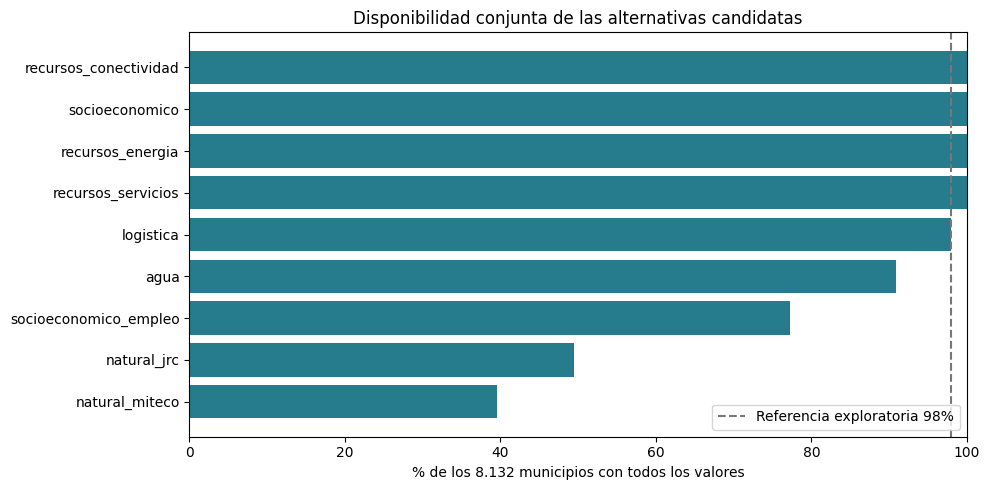

Cinco grupos; ninguna seleccion previa. Sin imputacion, pesos ni entrenamiento.


In [6]:
def matriz(ids):
    campos=['cod_ine']+[c for v in ids for c in (v,'estado__'+v,'nivel_origen__'+v)]
    return wide04[campos].copy()
matrices={g:matriz(vs) for g,vs in grupos.items()}
for c in ['cobertura_masas_pct']:
    if c in wide04: matrices['condicionantes_hidricos'][c]=wide04[c].to_numpy()

# Auxiliar experimental: no se anade al catalogo ni al consolidado.
aux='paro_por_100_hab_observado'
pop=pd.to_numeric(wide04['poblacion_2025'],errors='raise')
paro=pd.to_numeric(wide04['paro_total'],errors='raise')
publicado=wide04['estado__paro_total'].isin(['publicado','real','agregado_fusion_documentada'])
utilizable=publicado & paro.notna() & paro.ge(0) & pop.gt(0)
assert np.isfinite(paro[utilizable]).all()
review=wide04.copy()
review[aux]=(100*paro/pop).where(utilizable)
review['estado__'+aux]=np.where(utilizable,'derivado_datos_publicados','pendiente')
review['nivel_origen__'+aux]='municipio'

experimentos={
 'logistica':('logistica_industria',logvars),
 'agua':('condicionantes_hidricos',aguavars),
 'natural_jrc':('riesgos_naturales',[fire_rate,j100]),
 'natural_miteco':('riesgos_naturales',[fire_rate,mt]),
 'socioeconomico':('socioeconomico',sociovars),
 'socioeconomico_empleo':('socioeconomico',sociovars+[aux]),
 'recursos_servicios':('recursos_servicios',recvars),
 'recursos_energia':('recursos_servicios',recvars[:2]),
 'recursos_conectividad':('recursos_servicios',recvars[2:])}
assert set(g for g,vs in experimentos.values())==set(grupos)
assert not review[aux].loc[~utilizable].notna().any()
matrices_ml={k:review[['cod_ine']+[c for v in vs for c in (v,'estado__'+v,'nivel_origen__'+v)]].copy() for k,(g,vs) in experimentos.items()}
conjunta=pd.DataFrame([{'experimento':k,'grupo_tematico':g,'variables':'; '.join(vs),'municipios_completos':int(review[vs].notna().all(axis=1).sum()),'disponibilidad_conjunta_pct':100*review[vs].notna().all(axis=1).mean()} for k,(g,vs) in experimentos.items()])

# Correlaciones de todos los grupos y numero de pares realmente disponibles.
correlaciones=[]; distribuciones=[]
for g,vs in grupos.items():
    ids=vs+([aux] if g=='socioeconomico' else [])
    X=review[ids].apply(pd.to_numeric,errors='raise')
    corr=X.corr(method='spearman',min_periods=2)
    for i,a in enumerate(ids):
        v=X[a].dropna()
        distribuciones.append(dict(grupo_tematico=g,id_indicador=a,n=int(v.size),disponibilidad_pct=100*v.size/N,ceros=int(v.eq(0).sum()),p01=v.quantile(.01),p25=v.quantile(.25),mediana=v.median(),p75=v.quantile(.75),p99=v.quantile(.99)))
        for b in ids[i+1:]:
            correlaciones.append(dict(grupo_tematico=g,variable_a=a,variable_b=b,n_pares=int(X[[a,b]].notna().all(axis=1).sum()),rho_spearman=corr.loc[a,b]))
correlaciones=pd.DataFrame(correlaciones)
distribuciones=pd.DataFrame(distribuciones)
assert len(distribuciones)==44
assert all(len(t)==N and t.cod_ine.is_unique for t in matrices_ml.values())

# Cuadro de decisiones: una fila por grupo, sin puntuaciones ni seleccion anticipada.
resumen_grupos=pd.DataFrame([
 ('logistica_industria','Acceso y presencia industrial','Distancias rectas y suelo cartografiado, no parcela disponible'),
 ('condicionantes_hidricos','Presion hidrica y estado de acuiferos','Cobertura parcial y sin acreditacion de suministro'),
 ('riesgos_naturales','Historial de incendios y huella inundable','Ausencias ambiguas, distintas fuentes y escalas; no riesgo de parcela'),
 ('socioeconomico','Dinamica demografica y empleo registrado','Direccion dependiente de actividad; paro por habitante no tasa de paro'),
 ('recursos_servicios','Energia renovable y conectividad','Subdimensiones heterogeneas; electricidad provincial solo contexto')],columns=['grupo_tematico','utilidad_empresarial','limitacion_principal'])
resumen_grupos['indicadores_catalogo']=resumen_grupos.grupo_tematico.map({g:len(vs) for g,vs in grupos.items()})
resumen_grupos['decision']='pendiente_revision_conjunta'
resumen_grupos=resumen_grupos.merge(conjunta.groupby('grupo_tematico').disponibilidad_conjunta_pct.agg(disponibilidad_min_pct='min',disponibilidad_max_pct='max').reset_index(),on='grupo_tematico',validate='one_to_one')
display(resumen_grupos.round(2))
display(conjunta.round(2))
display(correlaciones.loc[correlaciones.rho_spearman.abs().ge(.85)].round(3))
fig,ax=plt.subplots(figsize=(10,5))
plot=conjunta.sort_values('disponibilidad_conjunta_pct')
ax.barh(plot.experimento,plot.disponibilidad_conjunta_pct,color='#267b8d')
ax.axvline(UMBRAL_COBERTURA,ls='--',color='#777777',label='Referencia exploratoria 98%')
ax.set(xlim=(0,100),xlabel='% de los 8.132 municipios con todos los valores',title='Disponibilidad conjunta de las alternativas candidatas')
ax.legend(loc='lower right');fig.tight_layout();plt.show();plt.close(fig)
print('Cinco grupos; ninguna seleccion previa. Sin imputacion, pesos ni entrenamiento.')

## 7. Exportación y handoff
Las salidas son candidatas de Data. Los notebooks 04–11 y la API siguen apuntando a v03 hasta que el equipo adopte el contrato nuevo. El indicador natural no se declara listo para un modelo nacional si no se resuelven sus huecos. La agrupación y los datos quedan disponibles sin esperar al entrenamiento.

Las matrices de los cinco grupos y sus alternativas se revisan conjuntamente. La eleccion de tres o cuatro dimensiones y su reduccion a una variable representativa por grupo quedan pendientes de resultados y acuerdo. Los notebooks de ML y la API no se modifican.

In [7]:
OUT.mkdir(parents=True,exist_ok=True)
def save(df,name):
    df.to_csv(OUT/name,index=False,encoding='utf-8-sig')
for tabla,nombre in [(municipios,'municipios.csv'),(ind04,'indicadores.csv'),(val04,'valores.csv'),(wide04,'dataset_municipal.csv'),(clas,'agrupacion_variables.csv'),(r,'trazabilidad_riesgos_01A.csv'),(inventario,'inventario_fuentes_01A.csv'),(geometrias,'calidad_geometrias_miteco.csv'),(comparacion,'discrepancias_jrc_miteco.csv'),(prov.reset_index(),'discrepancias_por_provincia.csv'),(proxy,'evaluacion_necesidad_proxy.csv'),(conjunta,'cobertura_matrices_candidatas.csv'),(resumen_grupos,'resumen_cinco_grupos.csv'),(correlaciones,'correlaciones_grupos.csv'),(distribuciones,'distribuciones_grupos.csv')]: save(tabla,nombre)
for g,tabla in matrices.items():
    assert len(tabla)==N and tabla.cod_ine.is_unique
    save(tabla,f'matriz_{g}.csv')
for g,tabla in matrices_ml.items(): save(tabla,f'candidatas_{g}.csv')
# Relectura de claves y dimensiones
assert len(pd.read_csv(OUT/'valores.csv',dtype={'cod_ine':str}))==N*43
assert set(pd.read_csv(OUT/'dataset_municipal.csv',dtype={'cod_ine':str}).cod_ine)==master
manifest=[]
for p in [BASE/'municipios.csv',BASE/'indicadores.csv',BASE/'valores.csv',BASE/'dataset_municipal.csv',NAT/'indicadores_riesgos_naturales_v01.csv',NAT/'inventario_fuentes_v01.csv',NAT/'calidad_geometrias_miteco_v01.csv']:
    manifest.append({'archivo':str(p.relative_to(ROOT)),'sha256':hashlib.sha256(p.read_bytes()).hexdigest()})
save(pd.DataFrame(manifest),'manifest_entradas.csv')
(OUT/'README.md').write_text('# SiteWise v04 candidata\n\n43 indicadores: 36 previos + 7 naturales. No sustituye v03. No apta para evaluar parcelas. NoData no se imputa. JRC y MITECO separados. Consultar agrupacion_variables.csv, cobertura_matrices_candidatas.csv y evaluacion_necesidad_proxy.csv antes de experimentar. Cinco grupos pendientes de seleccion conjunta. El paro por 100 habitantes observado es auxiliar experimental fuera del catalogo. Fuentes: JRC '+JRC+'; MITECO '+MIT+'; Civio '+CIV+'.\n',encoding='utf-8')
print('Salidas:',OUT)
print('Validaciones de integridad superadas. Sin validación predictiva ni publicación en app.')

Salidas: c:\PROYECTOS_ELE\Final_sidewise\data\processed\sitewise_v04_candidata
Validaciones de integridad superadas. Sin validación predictiva ni publicación en app.
